# Imports

In [1]:
import torch 
import torch.nn as nn
import math
import typing
from typing import List, Union
import pandas as pd
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt

# Dataset

In [13]:
df = pd.read_csv(r'df_trainset_v3.csv')
print(df.shape)
df.head(2)

(4606, 12)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,encode_position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.25,"[0.6820112650872491, 0.4728664244776024]",0.027811,"[-0.01566934209907833, -0.06868062391330976]",0.026323,"[-0.4258184861370507, -0.9048086078635362]",CTYTRCRZKVYTLGNIIWLC,[[0.20793835 0.32408492 0.3349807 0.68008423 ...,62,0.132196,63.0,1
1,0.55,"[0.663985472742647, 0.4591009778508717]",0.051235,"[-0.09298784207982802, -0.030763312846688873]",-4.067070,"[-0.8391207421663309, -0.5439451995065551]",RCRZCTYTKVYTLGNIIWLC,[[0.32408492 0.20793835 0.3349807 0.68008423 ...,260,0.554371,62.0,1


In [14]:
df['position_state_id'].nunique()

469

In [15]:
df['position_state_id'].describe()

count    4606.000000
mean      215.103995
std       134.838436
min         0.000000
25%        89.000000
50%       209.000000
75%       331.000000
max       468.000000
Name: position_state_id, dtype: float64

<Axes: >

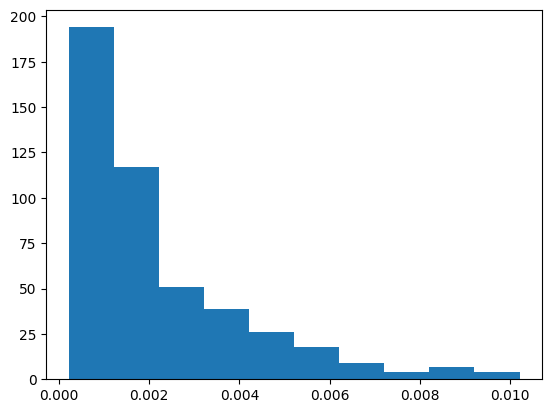

In [16]:
df['position_state_id'].value_counts(normalize=True).hist(grid=False, )

<Axes: >

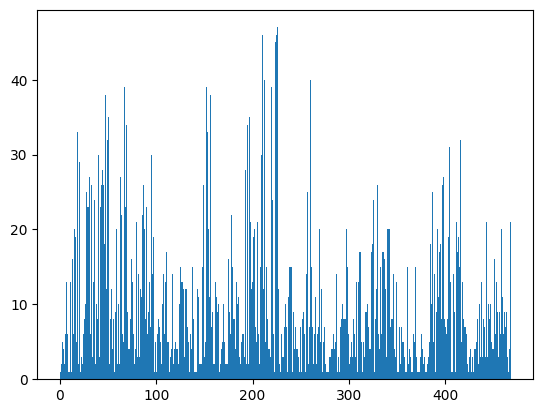

In [17]:
df['position_state_id'].hist(grid=False, bins=range(df['position_state_id'].nunique()))

## tokenized dataset

# Classes

## InputEmbeddings